# PSF, MTF and Strehl ratio

`pyoptics.imaging` describes a scalar imaging system by its pupil function
$P(\mathbf{k}_\perp) = A\,\exp(i\Phi)$ on the disk $|\mathbf{k}_\perp| \le k\,\mathrm{NA}$:

| Function | Result |
|---|---|
| `pupil_function()` | the sampled pupil $P$ (circular pupil times an optional mask $A$, times $\exp(i\Phi)$) |
| `get_psf()` | amplitude point spread function $h = \mathcal{F}^{-1}[P]$, by default normalized such that $\lvert h(0)\rvert^2$ is the Strehl ratio |
| `get_otf()`, `get_mtf()` | optical transfer function $\mathrm{OTF} = \mathcal{F}[\lvert h\rvert^2]/\mathcal{F}[\lvert h\rvert^2](0)$ and $\mathrm{MTF} = \lvert\mathrm{OTF}\rvert$ |
| `strehl_ratio()`, `rms_phase()`, `marechal_strehl()` | exact Strehl ratio, rms phase error and its Maréchal-type approximations |

Masks and phases are arrays on the frequency grid or callables of the
normalized pupil coordinates $(P_x, P_y) = (k_x, k_y)/(k\,\mathrm{NA})$, the
unit disk. Fringe Zernikes with `R_norm=1` evaluated at $(P_x, P_y)$ thus
give the usual pupil aberrations. `pyoptics.analytical` provides the
reference results: the Airy pattern, its encircled energy and the
diffraction limited OTF of a circular pupil.

**Convention:** $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$. A pupil phase
$k_x s$ therefore moves the PSF to $x = -s$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics import imaging
from pyoptics.analytical import airy_pattern, airy_encircled_energy, circular_otf
from pyoptics.bases import FringeZernikes
from pyoptics.utils import grid2d, freq_grid

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

wl, NA = 0.5, 0.25            # µm
k = 2*np.pi/wl
L, N = 64.0, 512              # dx = 0.125 µm = wl/(16 NA); pupil radius L*NA/wl = 32 samples
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
c = N//2
f = freq_grid(x, y, wavenumbers=False)[0][c]   # spatial frequencies in 1/µm
f_c = 2*NA/wl                                   # incoherent cut-off frequency

Z = FringeZernikes(x, y)  # only used to evaluate Zernikes at pupil coordinates (eval_single_scattered)

def zernike_phase(coeffs):
    """Pupil phase (callable) from {Fringe index: coefficient in waves}."""
    return lambda px, py: 2*np.pi*sum(a*Z.eval_single_scattered(px, py, j) for j, a in coeffs.items())

print(f"Airy radius 0.61 λ/NA = {0.61*wl/NA:.2f} µm, cut-off frequency 2NA/λ = {f_c:.2f} / µm")

Airy radius 0.61 λ/NA = 1.22 µm, cut-off frequency 2NA/λ = 1.00 / µm


## 1. The Airy pattern

Without aberrations, the intensity PSF of a circular pupil is the Airy pattern
$I(r) = \left(2 J_1(v)/v\right)^2$ with $v = 2\pi\,\mathrm{NA}\,r/\lambda$. Its
encircled energy is Rayleigh's $1 - J_0^2(v) - J_1^2(v)$: 83.8 % of the light
lies within the first dark ring at $0.61\,\lambda/\mathrm{NA}$, 91 % within the
second.

peak intensity: 1.0   max deviation from the Airy profile: 0.0008663177221973229


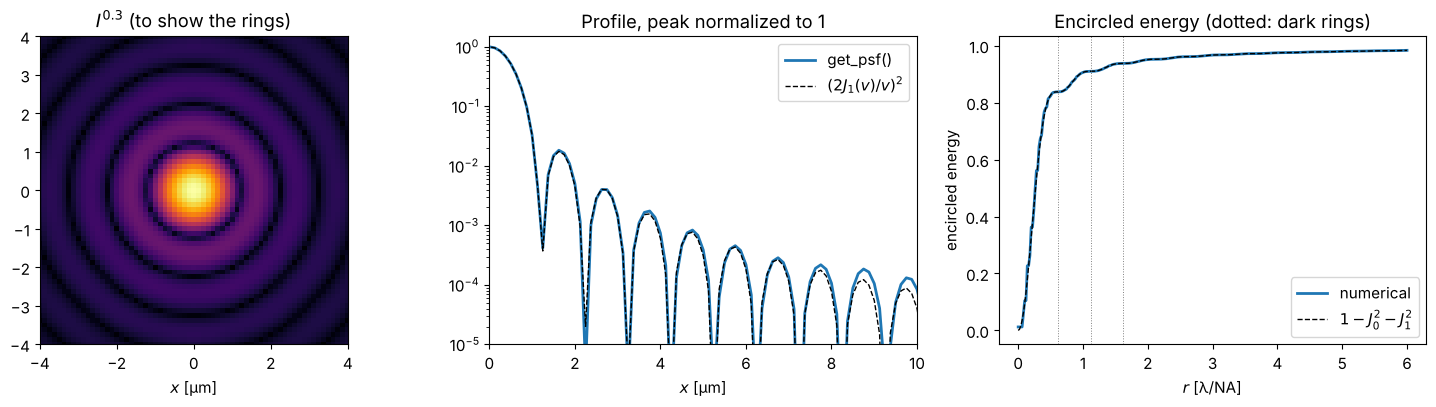

In [2]:
h = imaging.get_psf(x, y, NA, k)
I = np.abs(h)**2

r = np.hypot(X, Y)
r_bins = np.linspace(0, 6*wl/NA, 300)
EE = np.array([I[r <= rb].sum() for rb in r_bins])/I.sum()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ext = (x[0], x[-1], y[0], y[-1])
axes[0].imshow(I**0.3, extent=ext, cmap="inferno")
axes[0].set_xlim(-4, 4); axes[0].set_ylim(-4, 4)
axes[0].set_title("$I^{0.3}$ (to show the rings)"); axes[0].set_xlabel("$x$ [µm]")

axes[1].semilogy(x, I[c], lw=2, label="get_psf()")
axes[1].semilogy(x, airy_pattern(np.abs(x), NA, wl), "k--", lw=1, label="$(2J_1(v)/v)^2$")
axes[1].set_xlim(0, 10); axes[1].set_ylim(1E-5, 1.5)
axes[1].set_xlabel("$x$ [µm]"); axes[1].set_title("Profile, peak normalized to 1"); axes[1].legend()

axes[2].plot(r_bins*NA/wl, EE, lw=2, label="numerical")
axes[2].plot(r_bins*NA/wl, airy_encircled_energy(r_bins, NA, wl), "k--", lw=1, label="$1 - J_0^2 - J_1^2$")
for rz in (0.61, 1.12, 1.62):
    axes[2].axvline(rz, color="gray", lw=0.7, ls=":")
axes[2].set_xlabel("$r$ [λ/NA]"); axes[2].set_ylabel("encircled energy"); axes[2].legend()
axes[2].set_title("Encircled energy (dotted: dark rings)")
fig.tight_layout()

print("peak intensity:", I[c, c], "  max deviation from the Airy profile:",
      np.abs(I[c] - airy_pattern(np.abs(x), NA, wl)).max())

The small deviations come from the pupil: it is sampled on the frequency grid
with spacing $2\pi/L$, i.e. with about $L\,\mathrm{NA}/\lambda = 32$ samples across
its radius, so its edge is slightly staircased. A larger window $L$ samples the
pupil more finely.

## 2. MTF of a circular and of an obscured pupil

The OTF is the autocorrelation of the pupil. For a clear circular pupil it is
$\frac{2}{\pi}\left(\arccos s - s\sqrt{1-s^2}\right)$ with $s = f/f_c$ and the cut-off
$f_c = 2\,\mathrm{NA}/\lambda$, twice the coherent cut-off.

Telescopes often have a central obscuration (secondary mirror). The annular
pupil keeps the cut-off frequency but transfers less contrast at middle
frequencies and slightly more near the cut-off; in the PSF, the central peak
narrows and more energy moves into the rings.

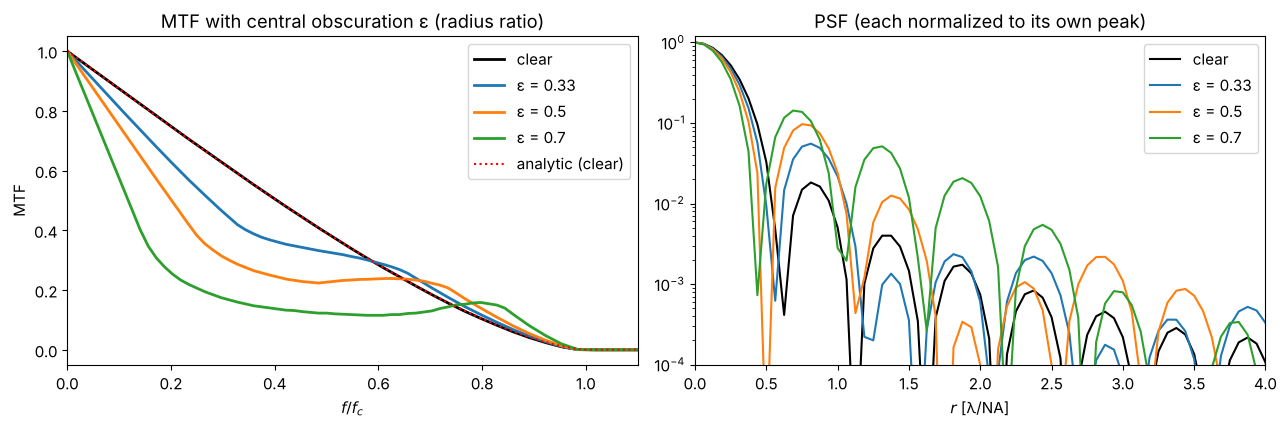

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for eps, color in zip((0.0, 0.33, 0.5, 0.7), ("k", "C0", "C1", "C2")):
    mask = (lambda px, py, e=eps: px**2 + py**2 >= e**2) if eps > 0 else None
    mtf = imaging.get_mtf(x, y, NA, k, pupil_mask=mask)
    psf = np.abs(imaging.get_psf(x, y, NA, k, pupil_mask=mask))**2
    label = "clear" if eps == 0 else f"ε = {eps}"
    axes[0].plot(f[c:]/f_c, mtf[c, c:], color=color, lw=2, label=label)
    axes[1].semilogy(x[c:]*NA/wl, psf[c, c:], color=color, lw=1.5, label=label)
axes[0].plot(f[c:]/f_c, circular_otf(f[c:], NA, wl), "r:", lw=1.5, label="analytic (clear)")
axes[0].set_xlim(0, 1.1); axes[0].set_xlabel("$f/f_c$"); axes[0].set_ylabel("MTF"); axes[0].legend()
axes[0].set_title("MTF with central obscuration ε (radius ratio)")
axes[1].set_xlim(0, 4); axes[1].set_ylim(1E-4, 1.2)
axes[1].set_xlabel("$r$ [λ/NA]"); axes[1].set_title("PSF (each normalized to its own peak)"); axes[1].legend()
fig.tight_layout()

## 3. Defocus: contrast loss and contrast reversal

With aberrations the OTF becomes complex and drops. Defocus is the classic
case (Hopkins 1955): beyond a defocus coefficient of about 0.32 λ (Fringe $Z_4$,
i.e. a peak-to-valley wavefront error of 0.64 λ) the OTF reaches zero at middle
frequencies and then turns **negative**: bars of that period are imaged with
inverted contrast (bright and dark swapped). The MTF only shows the modulus;
the real part of the OTF shows the sign change.

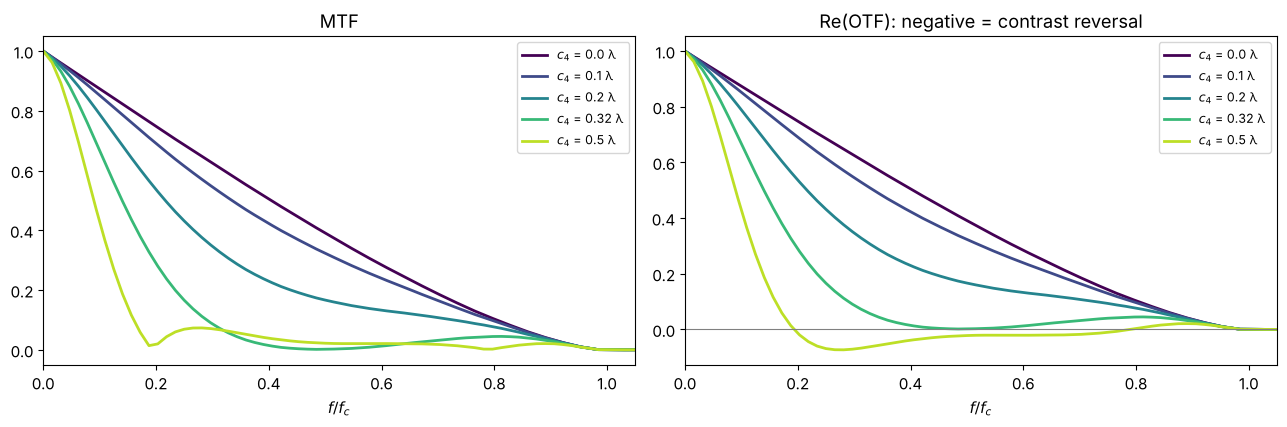

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for a, color in zip((0.0, 0.1, 0.2, 0.32, 0.5), plt.cm.viridis(np.linspace(0, 0.9, 5))):
    otf = imaging.get_otf(x, y, NA, k, phase=zernike_phase({4: a}))
    axes[0].plot(f[c:]/f_c, np.abs(otf[c, c:]), color=color, lw=2, label=f"$c_4$ = {a} λ")
    axes[1].plot(f[c:]/f_c, otf[c, c:].real, color=color, lw=2, label=f"$c_4$ = {a} λ")
axes[0].set_title("MTF"); axes[1].set_title("Re(OTF): negative = contrast reversal")
axes[1].axhline(0, color="gray", lw=0.8)
for ax in axes:
    ax.set_xlim(0, 1.05); ax.set_xlabel("$f/f_c$"); ax.legend(fontsize=9)
fig.tight_layout()

The contrast reversal is directly visible in the incoherent image of a
"chirped" bar pattern whose period decreases from left to right. With
$c_4 = 0.5$ λ the contrast vanishes at $f \approx 0.19 f_c$ and comes back
inverted beyond (compare the phase of the stripes with the object):

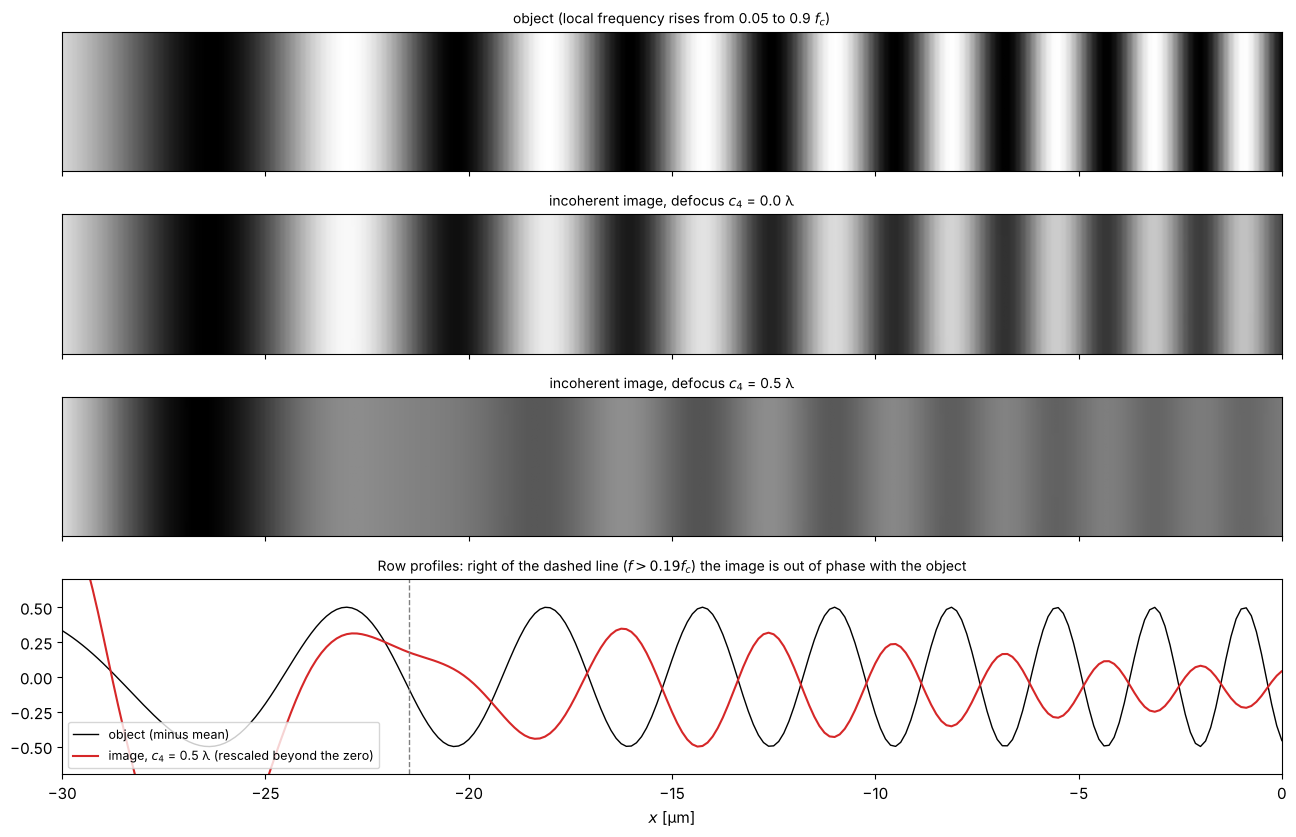

In [5]:
from pyoptics.fft import FT, inv_FT
f_local = f_c*(0.05 + 0.85*(X - x[0])/L)                       # local frequency rises along x
phase_chirp = 2*np.pi*np.cumsum(f_local, axis=1)*(x[1] - x[0])
obj = 0.5*(1 + np.cos(phase_chirp))*(np.abs(Y) < 20)

fig, axes = plt.subplots(4, 1, figsize=(13, 8.5), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1, 1, 1.4]})
images = {}
for ax, a in zip(axes, (None, 0.0, 0.5)):
    if a is None:
        img, title = obj, "object (local frequency rises from 0.05 to 0.9 $f_c$)"
    else:
        otf = imaging.get_otf(x, y, NA, k, phase=zernike_phase({4: a}))
        img = np.real(inv_FT(FT(obj)*otf))
        images[a] = img
        title = f"incoherent image, defocus $c_4$ = {a} λ"
    ax.imshow(img[c - 24:c + 24], extent=(x[0], x[-1], y[c - 24], y[c + 24]), cmap="gray", aspect="auto")
    ax.set_title(title, fontsize=10)
    ax.set_yticks([])
x_rev = x[0] + L*(0.19 - 0.05)/0.85   # where the local frequency reaches the zero of the OTF
modulation = images[0.5][c] - images[0.5][c].mean()
axes[3].plot(x, obj[c] - 0.5, "k-", lw=1, label="object (minus mean)")
axes[3].plot(x, modulation/np.abs(modulation[(x > x_rev + 2) & (x < 0)]).max()*0.5, "C3-", lw=1.5,
             label="image, $c_4$ = 0.5 λ (rescaled beyond the zero)")
axes[3].axvline(x_rev, color="gray", ls="--", lw=1)
axes[3].set_xlim(-30, 0); axes[3].set_ylim(-0.7, 0.7); axes[3].legend(fontsize=9, loc="lower left")
axes[3].set_title("Row profiles: right of the dashed line ($f > 0.19 f_c$) the image is out of phase with the object", fontsize=10)
axes[-1].set_xlabel("$x$ [µm]")
fig.tight_layout()

## 4. Strehl ratio and the Maréchal approximation

The Strehl ratio is the intensity at the Gaussian image point relative to
the aberration-free system,
$S = \lvert\langle e^{i\Phi}\rangle\rvert^2$, the average running over the pupil.
For small rms phase errors $\sigma$ (piston removed)

$$ S \approx 1 - \sigma^2 \approx \left(1 - \sigma^2/2\right)^2 \approx e^{-\sigma^2}. $$

The Maréchal criterion $S \ge 0.8$ corresponds to $\sigma \le 0.47$ rad, i.e. an
rms wavefront error of λ/14. The exponential form (Mahajan) holds to much larger
errors for most aberrations, but none of the approximations is universal:
the true $S$ depends on the shape of the aberration, not only on $\sigma$.

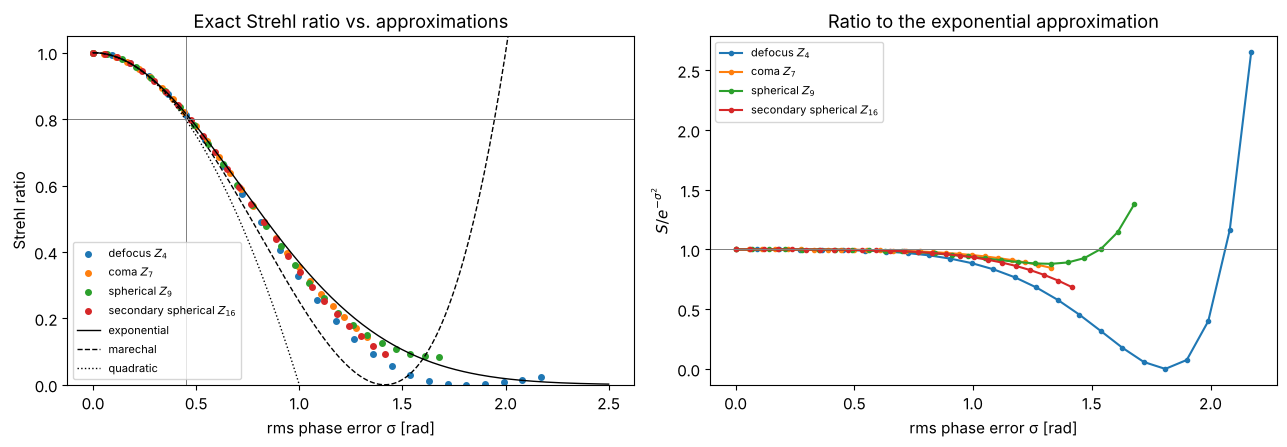

In [6]:
names = {4: "defocus $Z_4$", 7: "coma $Z_7$", 9: "spherical $Z_9$", 16: "secondary spherical $Z_{16}$"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
sigma_ref = np.linspace(0, 2.5, 200)
for j, name in names.items():
    amps = np.linspace(0, 0.6, 25)
    sig = [imaging.rms_phase(x, y, NA, k, phase=zernike_phase({j: a})) for a in amps]
    S = [imaging.strehl_ratio(x, y, NA, k, phase=zernike_phase({j: a})) for a in amps]
    axes[0].plot(sig, S, "o", ms=4, label=name)
    axes[1].plot(sig, np.array(S)/imaging.marechal_strehl(np.array(sig)), "o-", ms=3, label=name)
for approx, ls in (("exponential", "k-"), ("marechal", "k--"), ("quadratic", "k:")):
    axes[0].plot(sigma_ref, imaging.marechal_strehl(sigma_ref, approx), ls, lw=1, label=approx)
axes[0].axhline(0.8, color="gray", lw=0.7); axes[0].axvline(2*np.pi/14, color="gray", lw=0.7)
axes[0].set_ylim(0, 1.05); axes[0].set_xlabel("rms phase error σ [rad]"); axes[0].set_ylabel("Strehl ratio")
axes[0].set_title("Exact Strehl ratio vs. approximations"); axes[0].legend(fontsize=8)
axes[1].axhline(1, color="gray", lw=0.7)
axes[1].set_xlabel("rms phase error σ [rad]"); axes[1].set_ylabel("$S / e^{-σ^2}$")
axes[1].set_title("Ratio to the exponential approximation"); axes[1].legend(fontsize=8)
fig.tight_layout()

Because `get_psf()` normalizes to the aberration-free peak, the central value
of an aberrated intensity PSF *is* the Strehl ratio:

In [7]:
phase = zernike_phase({9: 0.1, 7: 0.05})
h_ab = imaging.get_psf(x, y, NA, k, phase=phase)
sigma = imaging.rms_phase(x, y, NA, k, phase=phase)
print(f"|h(0)|^2            = {np.abs(h_ab[c, c])**2:.4f}")
print(f"strehl_ratio()      = {imaging.strehl_ratio(x, y, NA, k, phase=phase):.4f}")
print(f"exp(-sigma^2)       = {imaging.marechal_strehl(sigma):.4f}   (sigma = {sigma:.3f} rad = λ/{2*np.pi/sigma:.1f})")

|h(0)|^2            = 0.9132
strehl_ratio()      = 0.9132
exp(-sigma^2)       = 0.9134   (sigma = 0.301 rad = λ/20.9)


## 5. Apodization

A pupil whose transmission falls off towards the edge (here a Gaussian
amplitude $A = \exp(-\rho^2/\rho_0^2)$) trades resolution for suppressed side
lobes: the central peak widens, the rings almost vanish. `pupil_mask` accepts
such real-valued masks. With the "peak" normalization, the aberration-free
apodized PSF again has the peak 1, so Strehl ratios refer to the apodized
system.

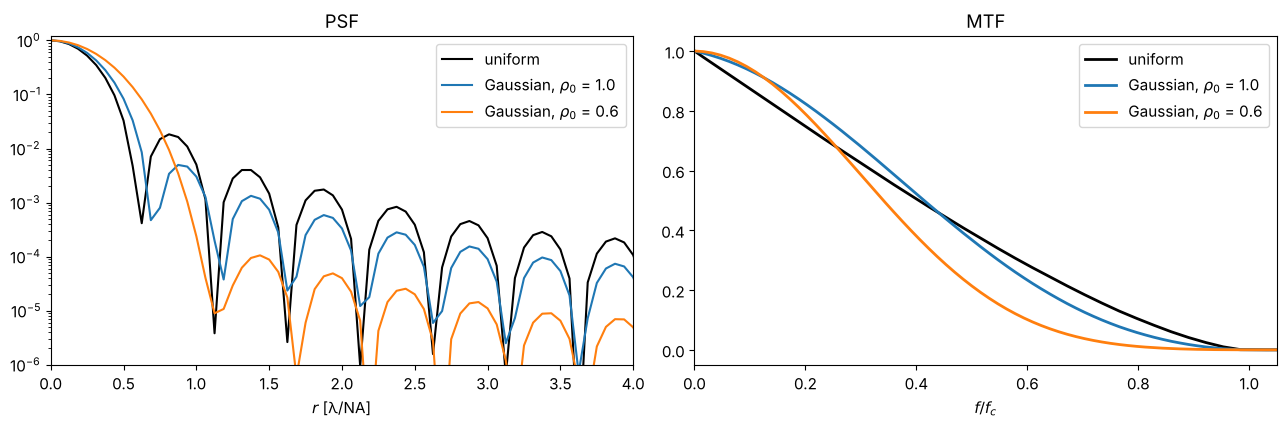

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for rho0, color in zip((None, 1.0, 0.6), ("k", "C0", "C1")):
    mask = None if rho0 is None else (lambda px, py, r0=rho0: np.exp(-(px**2 + py**2)/r0**2))
    I_ap = np.abs(imaging.get_psf(x, y, NA, k, pupil_mask=mask))**2
    mtf = imaging.get_mtf(x, y, NA, k, pupil_mask=mask)
    label = "uniform" if rho0 is None else f"Gaussian, $ρ_0$ = {rho0}"
    axes[0].semilogy(x[c:]*NA/wl, I_ap[c, c:], color=color, lw=1.5, label=label)
    axes[1].plot(f[c:]/f_c, mtf[c, c:], color=color, lw=2, label=label)
axes[0].set_xlim(0, 4); axes[0].set_ylim(1E-6, 1.2); axes[0].set_xlabel("$r$ [λ/NA]")
axes[0].set_title("PSF"); axes[0].legend()
axes[1].set_xlim(0, 1.05); axes[1].set_xlabel("$f/f_c$"); axes[1].set_title("MTF"); axes[1].legend()
fig.tight_layout()